# Big Data Lab End Semester Project
### Cargo 2000 Freight Tracking and Tracing - Descriptive and Predictive Analytics
**Roll No:** CS23I1012

**Dataset:** https://archive.ics.uci.edu/dataset/382/cargo+2000+freight+tracking+and+tracing

**Contents of this notebook**
1. About the dataset
2. Descriptive analytics - Data preprocessing (cleaning, selection, transformation)
3. Descriptive analytics - Visualization (14 plots with inferences)
4. Predictive analytics
   - 4.1 Association rules using Apriori
   - 4.2 Naive Bayes classifier
   - 4.3 Closed frequent itemsets using COFI
5. PySpark test drive (FP-Growth and Naive Bayes) and performance comparison
6. Final conclusion

**Assumed parameters (as allowed in the question):** min support = 0.10, min confidence = 0.70 (for Apriori and COFI), 80/20 train-test split for Naive Bayes.

## 1. About the dataset
The data is from a real freight forwarding company (Cargo 2000 standard). Every row is **one shipment** (a transport chain). A shipment has some **incoming legs** (i1, i2, i3) that bring the cargo to the hub, and one **outgoing leg** (o) that takes it to the customer.

Meaning of the column names (from the UCI description):
- `nr` - row number of the shipment
- `i1_`, `i2_`, `i3_` - the 1st, 2nd, 3rd incoming leg, `o_` - outgoing leg
- `legid` - id of the leg
- `rcs` - RCS (Receive at origin) event, `dep` - DEP (Depart) event, `rcf` - RCF (Arrive at destination) event, `dlv` - DLV (Deliver) event
- `dep_1`, `dep_2`, `dep_3` - 1st, 2nd, 3rd hop (flight) of the leg, `place` - id of the airport (anonymised)
- `_p` = **planned** duration (minutes), `_e` = **effective (actual)** duration (minutes)
- `hops` - number of hops (flights) in that leg, `legs` - number of incoming legs of the shipment

**My idea for the project:** the most useful thing to find out is *whether the final delivery of a shipment is late or not*. So I define
`o_dlv_e > o_dlv_p` => **Late**, otherwise **OnTime**. This will be the target for the classifier and also one of the items in association rules.

In [71]:
# importing the libraries needed
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time, warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
pd.set_option('display.max_columns', 40)

## 2. Descriptive Analytics - Data Preprocessing

### 2.0 Loading the data

In [72]:
# missing values are written as "?" in this file, so we tell pandas about it
df = pd.read_csv("c2k_data_comma.csv", na_values=["?"])
print("Shape when loaded:", df.shape)

# the last line of the file is an empty row, so remove completely empty rows
df = df.dropna(how='all').reset_index(drop=True)
print("Shape after removing empty row:", df.shape)

display(df.head())

Shape when loaded: (3943, 98)
Shape after removing empty row: (3942, 98)


,nr,i1_legid,i1_rcs_p,i1_rcs_e,i1_dep_1_p,i1_dep_1_e,i1_dep_1_place,i1_rcf_1_p,i1_rcf_1_e,i1_rcf_1_place,i1_dep_2_p,i1_dep_2_e,i1_dep_2_place,i1_rcf_2_p,i1_rcf_2_e,i1_rcf_2_place,i1_dep_3_p,i1_dep_3_e,i1_dep_3_place,i1_rcf_3_p,...,o_dep_1_place,o_rcf_1_p,o_rcf_1_e,o_rcf_1_place,o_dep_2_p,o_dep_2_e,o_dep_2_place,o_rcf_2_p,o_rcf_2_e,o_rcf_2_place,o_dep_3_p,o_dep_3_e,o_dep_3_place,o_rcf_3_p,o_rcf_3_e,o_rcf_3_place,o_dlv_p,o_dlv_e,o_hops,legs
0,0.0,5182.0,199.0,218.0,210.0,215.0,609.0,935.0,736.0,256.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,256.0,1330.0,1265.0,411.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,780.0,434.0,1.0,2.0
1,1.0,6523.0,844.0,584.0,90.0,297.0,700.0,1935.0,1415.0,431.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,431.0,835.0,526.0,256.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3870.0,445.0,1.0,2.0
2,2.0,5878.0,4380.0,4119.0,90.0,280.0,456.0,905.0,547.0,700.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,700.0,1200.0,1280.0,349.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,550.0,1520.0,1.0,1.0
3,3.0,1275.0,759.0,169.0,240.0,777.0,173.0,340.0,577.0,349.0,1340.0,1109.0,349.0,1240.0,820.0,671.0,NaN,NaN,NaN,NaN,...,671.0,815.0,956.0,700.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3780.0,159.0,1.0,1.0
4,4.0,8117.0,1597.0,1485.0,150.0,241.0,411.0,585.0,612.0,128.0,340.0,289.0,128.0,130.0,135.0,166.0,NaN,NaN,NaN,NaN,...,166.0,230.0,167.0,128.0,810.0,872.0,128.0,740.0,346.0,411.0,NaN,NaN,NaN,NaN,NaN,NaN,4140.0,4797.0,2.0,1.0


In [73]:
print("Number of columns of each type:")
print(df.dtypes.astype(str).value_counts())

print("\nBasic statistics of some important columns")
display(df[['legs','i1_hops','o_hops','i1_dlv_p','i1_dlv_e','o_dlv_p','o_dlv_e']].describe().T)

Number of columns of each type:
float64    98
Name: count, dtype: int64

Basic statistics of some important columns


,count,mean,std,min,25%,50%,75%,max
legs,3942.0,2.012177,0.825165,1.0,1.0,2.0,3.00,3.0
i1_hops,3942.0,1.308980,0.474592,1.0,1.0,1.0,2.00,3.0
o_hops,3942.0,1.474632,0.512459,1.0,1.0,1.0,2.00,3.0
i1_dlv_p,3942.0,3694.260020,1702.124454,180.0,3420.0,3780.0,4230.00,9915.0
i1_dlv_e,3942.0,2251.035515,5585.187581,1.0,212.0,863.0,2176.00,90977.0
o_dlv_p,3942.0,3573.239726,1734.596116,240.0,2880.0,3780.0,4080.00,11520.0
o_dlv_e,3942.0,3698.563673,14422.433250,1.0,400.0,1201.5,3174.25,560130.0


### 2.1 Data Cleaning
Cleaning is done in these steps: (a) missing values, (b) data types, (c) duplicates, (d) invalid / noisy values, (e) outliers.

#### (a) Missing values

In [74]:
missing_count = df.isnull().sum()
missing_summary = pd.DataFrame({'Missing_Count': missing_count,
                                'Missing_Percentage': (missing_count / len(df)) * 100})
missing_summary = missing_summary.sort_values('Missing_Percentage', ascending=False)

print("Columns having missing values:", (missing_summary['Missing_Count'] > 0).sum(), "out of", df.shape[1])
display(missing_summary[missing_summary['Missing_Count'] > 0].head(15))

Columns having missing values: 72 out of 98


,Missing_Count,Missing_Percentage
i3_dep_3_e,3934,99.797057
i3_dep_3_p,3934,99.797057
i3_dep_3_place,3934,99.797057
i3_rcf_3_p,3934,99.797057
i3_rcf_3_e,3934,99.797057
i3_rcf_3_place,3934,99.797057
i2_dep_3_e,3928,99.644850
i2_dep_3_p,3928,99.644850
i2_rcf_3_e,3928,99.644850
i2_rcf_3_place,3928,99.644850


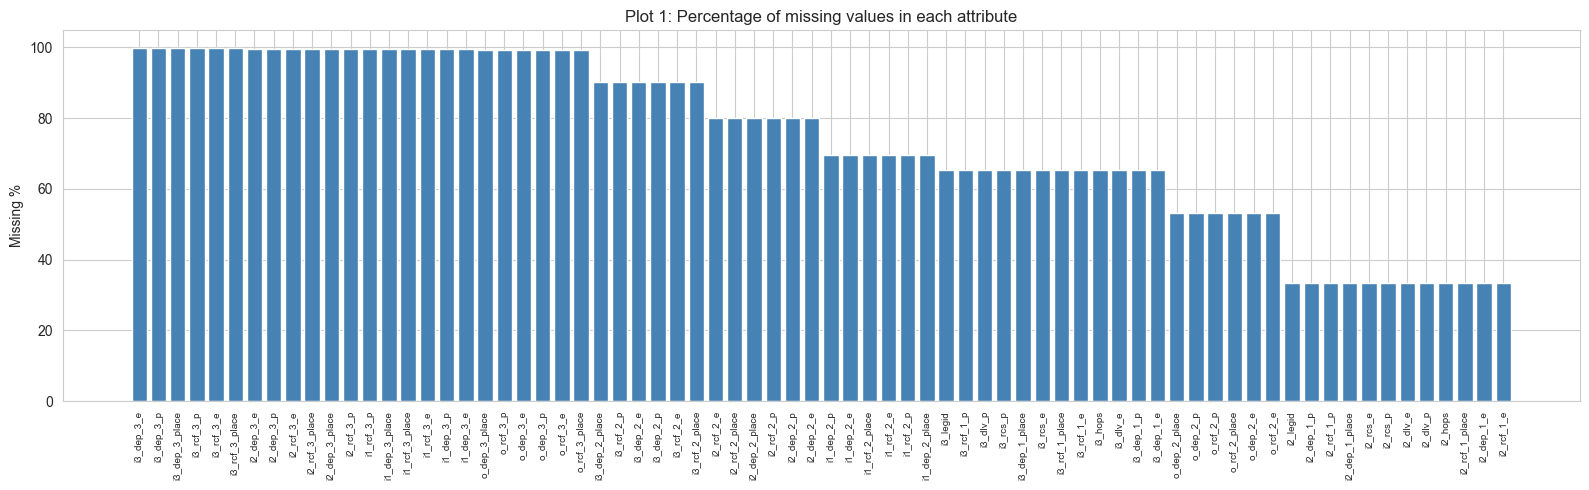

In [75]:
# PLOT 1 : Bar chart of missing value percentage
miss_cols = missing_summary[missing_summary['Missing_Count'] > 0]

plt.figure(figsize=(16, 5))
plt.bar(miss_cols.index, miss_cols['Missing_Percentage'], color='steelblue')
plt.xticks(rotation=90, fontsize=7)
plt.ylabel("Missing %")
plt.title("Plot 1: Percentage of missing values in each attribute")
plt.tight_layout()
plt.show()

In [76]:
# Check 1: i2 columns are empty exactly when legs == 1, and i3 columns empty exactly when legs < 3
print("i2 missing exactly when legs==1 :", ((df['legs'] == 1) == df['i2_legid'].isna()).all())
print("i3 missing exactly when legs<3  :", ((df['legs'] < 3) == df['i3_legid'].isna()).all())

# Check 2: number of hops should match the number of hop columns that are filled
for p in ['i1', 'i2', 'i3', 'o']:
    n_filled = df[[f'{p}_dep_{k}_p' for k in (1, 2, 3)]].notna().sum(axis=1)
    ok = ((n_filled == df[f'{p}_hops']) | df[f'{p}_hops'].isna()).all()
    print(f"{p}_hops matches filled hop columns :", ok)

print("\nShipments by number of legs:")
print(df['legs'].value_counts().sort_index())
print("\nOutgoing leg hops:")
print(df['o_hops'].value_counts().sort_index())

i2 missing exactly when legs==1 : True
i3 missing exactly when legs<3  : True
i1_hops matches filled hop columns : True
i2_hops matches filled hop columns : True
i3_hops matches filled hop columns : True
o_hops matches filled hop columns : True

Shipments by number of legs:
legs
1.0    1318
2.0    1258
3.0    1366
Name: count, dtype: int64

Outgoing leg hops:
o_hops
1.0    2097
2.0    1819
3.0      26
Name: count, dtype: int64


In [77]:
# dropping 3rd hop columns (almost completely empty)
hop3_cols = [c for c in df.columns if '_dep_3_' in c or '_rcf_3_' in c]
print("Dropping", len(hop3_cols), "columns")
df = df.drop(columns=hop3_cols)
print("New shape:", df.shape)

Dropping 24 columns
New shape: (3942, 74)


#### (b) Correcting the data types

In [78]:
id_cols = [c for c in df.columns if c.endswith('_legid') or c.endswith('_place')]
df[id_cols] = df[id_cols].astype('Int64').astype('category')

count_cols = ['legs'] + [c for c in df.columns if c.endswith('_hops')]
df[count_cols] = df[count_cols].astype('Int64')
df['nr'] = df['nr'].astype(int)

print(df.dtypes.astype(str).value_counts())
print("\nNumber of different airports (places) in o_dep_1_place:", df['o_dep_1_place'].nunique())

float64     48
category    20
Int64        5
int64        1
Name: count, dtype: int64

Number of different airports (places) in o_dep_1_place: 122


#### (c) Duplicate records

In [79]:
print("Duplicate rows (ignoring nr):", df.drop(columns='nr').duplicated().sum())
print("Is nr unique? ", df['nr'].is_unique)
print("Unique i1_legid:", df['i1_legid'].nunique(), " of ", len(df), "rows")
print("Unique o_legid :", df['o_legid'].nunique(), " of ", len(df), "rows")

Duplicate rows (ignoring nr): 0
Is nr unique?  True
Unique i1_legid: 3942  of  3942 rows
Unique o_legid : 3942  of  3942 rows


#### (d) Invalid / noisy values
Durations in minutes cannot be zero or negative. Also hops and legs must be between 1 and 3. Let's check all planned (`_p`) and effective (`_e`) columns.

In [80]:
dur_cols = [c for c in df.columns if c.endswith('_p') or c.endswith('_e')]
print("Number of duration columns checked:", len(dur_cols))

neg = (df[dur_cols] <= 0).sum()
print("Columns having zero / negative durations:", (neg > 0).sum())

print("legs range :", df['legs'].min(), "-", df['legs'].max())
print("hops range :", df[[c for c in df.columns if c.endswith('_hops')]].min().min(), "-",
      df[[c for c in df.columns if c.endswith('_hops')]].max().max())

Number of duration columns checked: 48
Columns having zero / negative durations: 0
legs range : 1 - 3
hops range : 1 - 3


#### (e) Outliers
Delivery durations are the main variable of this project, so I check outliers in the 4 delivery columns using the **IQR rule** (value > Q3 + 1.5 IQR).

In [81]:
dlv_e_cols = ['i1_dlv_e', 'i2_dlv_e', 'i3_dlv_e', 'o_dlv_e']

rows = []
for c in dlv_e_cols:
    s = df[c].dropna().astype(float)
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    upper = q3 + 1.5 * (q3 - q1)
    n_out = (s > upper).sum()
    rows.append([c, len(s), q1, q3, upper, n_out, round(100 * n_out / len(s), 1), s.max()])

iqr_table = pd.DataFrame(rows, columns=['column', 'count', 'Q1', 'Q3', 'upper_limit', 'n_outliers', 'outlier_%', 'max'])
display(iqr_table)

,column,count,Q1,Q3,upper_limit,n_outliers,outlier_%,max
0,i1_dlv_e,3942,212.0,2176.00,5122.000,340,8.6,90977.0
1,i2_dlv_e,2624,220.0,1957.25,4563.125,252,9.6,527290.0
2,i3_dlv_e,1366,220.5,2175.25,5107.375,122,8.9,123349.0
3,o_dlv_e,3942,400.0,3174.25,7335.625,424,10.8,560130.0


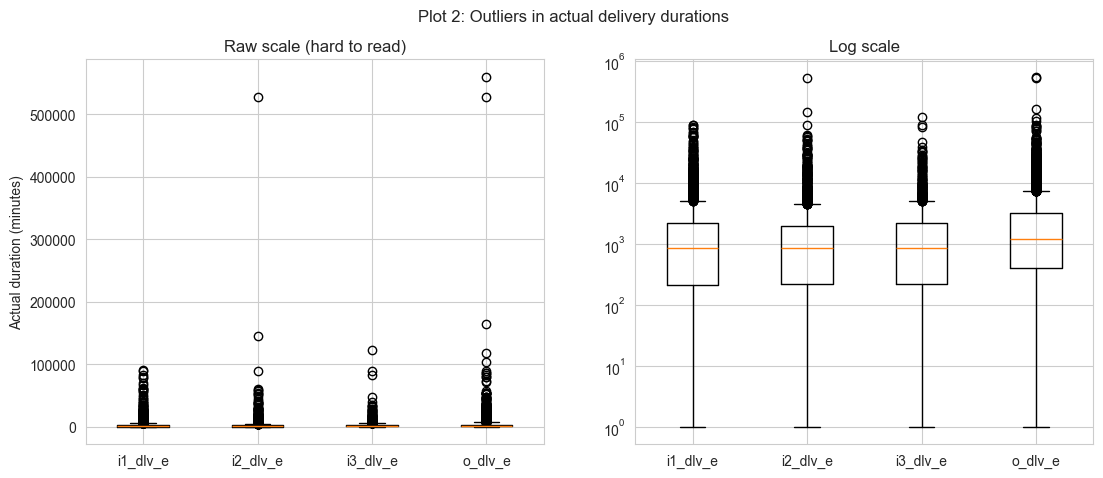

Largest 5 values of o_dlv_e: [560130.0, 527179.0, 164623.0, 118585.0, 103870.0]
Largest planned o_dlv_p     : 11520.0 minutes = 8.0 days


In [82]:
# PLOT 2 : Boxplot of the actual delivery durations (normal scale and log scale)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].boxplot([df[c].dropna().astype(float) for c in dlv_e_cols])
ax[0].set_xticklabels(dlv_e_cols)
ax[0].set_title("Raw scale (hard to read)")
ax[0].set_ylabel("Actual duration (minutes)")

ax[1].boxplot([df[c].dropna().astype(float) for c in dlv_e_cols])
ax[1].set_xticklabels(dlv_e_cols)
ax[1].set_yscale('log')
ax[1].set_title("Log scale")

plt.suptitle("Plot 2: Outliers in actual delivery durations")
plt.show()

print("Largest 5 values of o_dlv_e:", df['o_dlv_e'].nlargest(5).tolist())
print("Largest planned o_dlv_p     :", df['o_dlv_p'].max(), "minutes =", round(df['o_dlv_p'].max()/1440, 1), "days")

In [83]:
limit = 43200   # 30 days in minutes
noisy = (df[dlv_e_cols].astype(float) > limit).any(axis=1)
print("Rows removed as noise:", noisy.sum(), "(", round(100 * noisy.mean(), 2), "% of data )")

df_clean = df[~noisy].reset_index(drop=True)
print("Shape before:", df.shape, " after:", df_clean.shape)
print("New max of o_dlv_e:", df_clean['o_dlv_e'].max())

Rows removed as noise: 59 ( 1.5 % of data )
Shape before: (3942, 74)  after: (3883, 74)
New max of o_dlv_e: 43161.0


**Summary of cleaning:** removed 1 empty row, dropped 3rd-hop columns (structurally empty, > 99 % missing), corrected data types, checked duplicates & invalid values (none), removed the noisy rows with unrealistic delivery time. Structural NaNs of leg 2 / leg 3 are kept on purpose.

### 2.2 Data Selection

In [84]:
keep = ['legs'] + [f'{p}_hops' for p in ['i1', 'i2', 'i3', 'o']]
for p in ['i1', 'i2', 'i3', 'o']:
    keep += [f'{p}_rcs_p', f'{p}_rcs_e', f'{p}_dlv_p', f'{p}_dlv_e']
for p in ['i1', 'o']:
    keep += [f'{p}_dep_1_p', f'{p}_dep_1_e', f'{p}_dep_1_place',
             f'{p}_rcf_1_p', f'{p}_rcf_1_e', f'{p}_rcf_1_place']

df_sel = df_clean[keep].copy()
print("Attributes before selection:", df_clean.shape[1], " after selection:", df_sel.shape[1])
print(df_sel.columns.tolist())

Attributes before selection: 74  after selection: 33
['legs', 'i1_hops', 'i2_hops', 'i3_hops', 'o_hops', 'i1_rcs_p', 'i1_rcs_e', 'i1_dlv_p', 'i1_dlv_e', 'i2_rcs_p', 'i2_rcs_e', 'i2_dlv_p', 'i2_dlv_e', 'i3_rcs_p', 'i3_rcs_e', 'i3_dlv_p', 'i3_dlv_e', 'o_rcs_p', 'o_rcs_e', 'o_dlv_p', 'o_dlv_e', 'i1_dep_1_p', 'i1_dep_1_e', 'i1_dep_1_place', 'i1_rcf_1_p', 'i1_rcf_1_e', 'i1_rcf_1_place', 'o_dep_1_p', 'o_dep_1_e', 'o_dep_1_place', 'o_rcf_1_p', 'o_rcf_1_e', 'o_rcf_1_place']


### 2.3 Data Transformation
The algorithms need data in different forms, so I create 3 versions of the selected data:
1. **Numeric version** 
2. **Categorical version** 
3. **Transaction version** 

In [85]:
def status(p, e):
    # Late if actual > planned, OnTime otherwise, NoLeg if the leg does not exist
    p = p.astype(float); e = e.astype(float)
    return pd.Series(np.where(e.isna(), 'NoLeg', np.where(e > p, 'Late', 'OnTime')), index=p.index)

num = pd.DataFrame(index=df_sel.index)
num['legs']    = df_sel['legs'].astype(int)
num['i1_hops'] = df_sel['i1_hops'].astype(int)
num['o_hops']  = df_sel['o_hops'].astype(int)

# keeping the needed durations as float
for c in ['i1_rcs_p','i1_rcs_e','i1_dlv_p','i1_dlv_e','o_rcs_p','o_rcs_e',
          'o_dep_1_p','o_dep_1_e','o_dlv_p','o_dlv_e']:
    num[c] = df_sel[c].astype(float)

# delay in minutes (positive means late)
num['i1_delay'] = num['i1_dlv_e'] - num['i1_dlv_p']
num['o_delay']  = num['o_dlv_e']  - num['o_dlv_p']

# status of every important event
stat = {}
for p in ['i1', 'i2', 'i3', 'o']:
    stat[p + '_dlv'] = status(df_sel[p + '_dlv_p'], df_sel[p + '_dlv_e'])
    stat[p + '_rcs'] = status(df_sel[p + '_rcs_p'], df_sel[p + '_rcs_e'])
stat = pd.DataFrame(stat)

num['o_status'] = stat['o_dlv']                                   # TARGET : Late / OnTime
num['n_late_incoming'] = (stat[['i1_dlv', 'i2_dlv', 'i3_dlv']] == 'Late').sum(axis=1)

print(num['o_status'].value_counts())
print(num['o_status'].value_counts(normalize=True).round(3))
display(num.head())

o_status
OnTime    2754
Late      1129
Name: count, dtype: int64
o_status
OnTime    0.709
Late      0.291
Name: proportion, dtype: float64


,legs,i1_hops,o_hops,i1_rcs_p,i1_rcs_e,i1_dlv_p,i1_dlv_e,o_rcs_p,o_rcs_e,o_dep_1_p,o_dep_1_e,o_dlv_p,o_dlv_e,i1_delay,o_delay,o_status,n_late_incoming
0,2,1,1,199.0,218.0,840.0,1539.0,9919.0,7559.0,240.0,2865.0,780.0,434.0,699.0,-346.0,OnTime,1
1,2,1,1,844.0,584.0,3780.0,5790.0,3030.0,3016.0,300.0,286.0,3870.0,445.0,2010.0,-3425.0,OnTime,1
2,1,1,1,4380.0,4119.0,3780.0,321.0,1433.0,642.0,240.0,969.0,550.0,1520.0,-3459.0,970.0,Late,0
3,1,2,1,759.0,169.0,335.0,535.0,3963.0,3176.0,90.0,883.0,3780.0,159.0,200.0,-3621.0,OnTime,1
4,1,2,2,1597.0,1485.0,4230.0,1255.0,152.0,179.0,180.0,131.0,4140.0,4797.0,-2975.0,657.0,Late,0


**Step 2: Log transformation and Min-Max scaling.** 

In [86]:
from sklearn.preprocessing import MinMaxScaler

dur_num_cols = ['i1_rcs_p','i1_rcs_e','i1_dlv_p','i1_dlv_e','o_rcs_p','o_rcs_e','o_dep_1_p','o_dep_1_e','o_dlv_p','o_dlv_e']
print("Skewness before log:\n", num[dur_num_cols].skew().round(2).to_dict())

num_log = np.log10(num[dur_num_cols])
print("\nSkewness after log :\n", num_log.skew().round(2).to_dict())

scaled = pd.DataFrame(MinMaxScaler().fit_transform(num_log), columns=[c + '_scaled' for c in dur_num_cols])
display(scaled.describe().loc[['min', 'max', 'mean']].round(3))

Skewness before log:
 {'i1_rcs_p': 5.74, 'i1_rcs_e': 5.94, 'i1_dlv_p': -0.1, 'i1_dlv_e': 4.88, 'o_rcs_p': 4.84, 'o_rcs_e': 5.06, 'o_dep_1_p': 3.55, 'o_dep_1_e': 4.3, 'o_dlv_p': -0.05, 'o_dlv_e': 3.61}

Skewness after log :
 {'i1_rcs_p': -0.11, 'i1_rcs_e': -0.06, 'i1_dlv_p': -1.67, 'i1_dlv_e': -0.67, 'o_rcs_p': -0.18, 'o_rcs_e': -0.38, 'o_dep_1_p': 0.62, 'o_dep_1_e': -0.09, 'o_dlv_p': -1.52, 'o_dlv_e': -0.75}


,i1_rcs_p_scaled,i1_rcs_e_scaled,i1_dlv_p_scaled,i1_dlv_e_scaled,o_rcs_p_scaled,o_rcs_e_scaled,o_dep_1_p_scaled,o_dep_1_e_scaled,o_dlv_p_scaled,o_dlv_e_scaled
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
max,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
mean,0.569,0.551,0.704,0.608,0.609,0.601,0.225,0.528,0.642,0.646


**Step 3: Categorical version (discretization).** 

In [87]:
ml_all = pd.DataFrame(index=df_sel.index)
ml_all['legs']    = 'legs=' + num['legs'].astype(str)
ml_all['i1_hops'] = 'i1_hops=' + num['i1_hops'].astype(str)
ml_all['o_hops']  = 'o_hops=' + num['o_hops'].astype(str)

for p in ['i1', 'i2', 'i3']:
    ml_all[p + '_dlv'] = p + '_dlv=' + stat[p + '_dlv']
ml_all['i1_rcs'] = 'i1_rcs=' + stat['i1_rcs']
ml_all['o_rcs']  = 'o_rcs='  + stat['o_rcs']

ml_all['o_dlv_plan']  = 'o_dlv_plan=' + pd.cut(num['o_dlv_p'], [0, 3000, 3780, 4500, 20000],
                                               labels=['Short', 'Normal', 'Long', 'VeryLong']).astype(str)
ml_all['i1_rcs_plan'] = 'i1_rcs_plan=' + pd.qcut(num['i1_rcs_p'], 3, labels=['Low', 'Mid', 'High']).astype(str)

top_places = df_sel['o_dep_1_place'].value_counts().head(6).index
ml_all['o_dep_place'] = 'o_dep_place=' + np.where(df_sel['o_dep_1_place'].isin(top_places),
                                                  df_sel['o_dep_1_place'].astype(str), 'Other')

y = stat['o_dlv'].copy()          # target label
display(ml_all.head())
print("Target distribution:\n", y.value_counts())

,legs,i1_hops,o_hops,i1_dlv,i2_dlv,i3_dlv,i1_rcs,o_rcs,o_dlv_plan,i1_rcs_plan,o_dep_place
0,legs=2,i1_hops=1,o_hops=1,i1_dlv=Late,i2_dlv=OnTime,i3_dlv=NoLeg,i1_rcs=Late,o_rcs=OnTime,o_dlv_plan=Short,i1_rcs_plan=Low,o_dep_place=Other
1,legs=2,i1_hops=1,o_hops=1,i1_dlv=Late,i2_dlv=OnTime,i3_dlv=NoLeg,i1_rcs=OnTime,o_rcs=OnTime,o_dlv_plan=Long,i1_rcs_plan=Mid,o_dep_place=Other
2,legs=1,i1_hops=1,o_hops=1,i1_dlv=OnTime,i2_dlv=NoLeg,i3_dlv=NoLeg,i1_rcs=OnTime,o_rcs=OnTime,o_dlv_plan=Short,i1_rcs_plan=High,o_dep_place=700
3,legs=1,i1_hops=2,o_hops=1,i1_dlv=Late,i2_dlv=NoLeg,i3_dlv=NoLeg,i1_rcs=OnTime,o_rcs=OnTime,o_dlv_plan=Normal,i1_rcs_plan=Mid,o_dep_place=671
4,legs=1,i1_hops=2,o_hops=2,i1_dlv=OnTime,i2_dlv=NoLeg,i3_dlv=NoLeg,i1_rcs=OnTime,o_rcs=Late,o_dlv_plan=Long,i1_rcs_plan=High,o_dep_place=Other


Target distribution:
 o_dlv
OnTime    2754
Late      1129
Name: count, dtype: int64


**Step 4: Relevance of the attributes (Mutual Information).** 

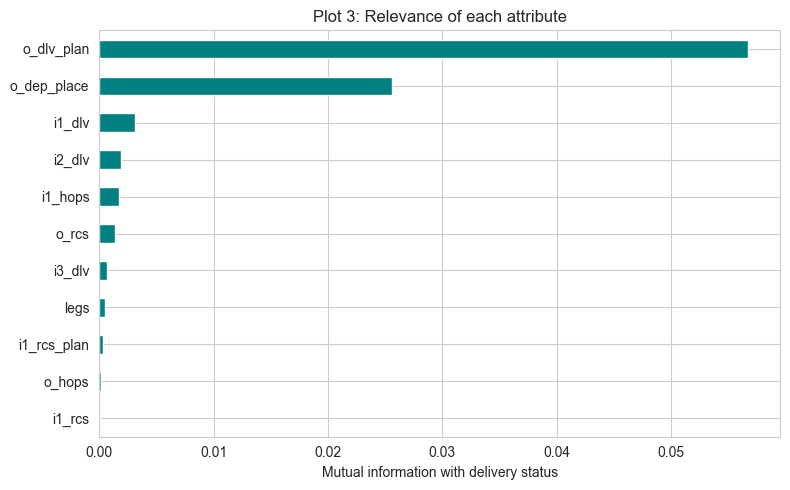

o_dlv_plan     0.0567
o_dep_place    0.0256
i1_dlv         0.0032
i2_dlv         0.0019
i1_hops        0.0017
o_rcs          0.0014
i3_dlv         0.0007
legs           0.0005
i1_rcs_plan    0.0003
o_hops         0.0001
i1_rcs         0.0001
dtype: float64


In [88]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split

# First, divide the dataset into training and testing sets
train_idx, test_idx = train_test_split(
    np.arange(len(ml_all)),
    test_size=0.2,
    stratify=y,
    random_state=42
)

# Encode categorical attributes
# This encoding uses no target information
enc_all = OrdinalEncoder()
X_all = enc_all.fit_transform(ml_all)

# Calculate mutual information using only training data
X_train_all = X_all[train_idx]
y_train_cv = y.iloc[train_idx].reset_index(drop=True)

mi = mutual_info_classif(
    X_train_all,
    y_train_cv,
    discrete_features=True,
    random_state=0
)

mi = pd.Series(mi, index=ml_all.columns).sort_values()

# PLOT 3: Mutual information
plt.figure(figsize=(8, 5))
mi.plot(kind='barh', color='teal')
plt.xlabel("Mutual information with delivery status")
plt.title("Plot 3: Relevance of each attribute")
plt.tight_layout()
plt.show()

print(mi.round(4).sort_values(ascending=False))

In [89]:
from sklearn.naive_bayes import CategoricalNB
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

cv = StratifiedKFold(5, shuffle=True, random_state=1)

thresholds = [0.0, 0.001, 0.002, 0.005]
cv_results = {}

for thr in thresholds:

    fold_scores = []

    # Perform 5-fold cross-validation on training data
    for tr_idx, val_idx in cv.split(X_train_all, y_train_cv):

        X_tr = X_train_all[tr_idx]
        X_val = X_train_all[val_idx]

        y_tr = y_train_cv.iloc[tr_idx]
        y_val = y_train_cv.iloc[val_idx]

        # Calculate MI using only the current training fold
        mi_fold = mutual_info_classif(
            X_tr,
            y_tr,
            discrete_features=True,
            random_state=0
        )

        # Select features based on the threshold
        selected_idx = np.where(mi_fold >= thr)[0]

        # If no feature is selected, use the best one
        if len(selected_idx) == 0:
            selected_idx = [np.argmax(mi_fold)]

        # Train and evaluate Naive Bayes
        model = CategoricalNB()
        model.fit(X_tr[:, selected_idx], y_tr)

        predictions = model.predict(X_val[:, selected_idx])

        fold_scores.append(accuracy_score(y_val, predictions))

    cv_results[thr] = np.mean(fold_scores)

    print(
        f"MI >= {thr:<6} -> "
        f"CV accuracy = {cv_results[thr]:.4f}"
    )

MI >= 0.0    -> CV accuracy = 0.7399
MI >= 0.001  -> CV accuracy = 0.7447
MI >= 0.002  -> CV accuracy = 0.7421
MI >= 0.005  -> CV accuracy = 0.7473


In [128]:
# Threshold selected based on cross-validation results
SEL_THR = 0.005

print("Selected MI threshold:", SEL_THR)
print("Cross-validation accuracy:", round(cv_results[SEL_THR], 4))

Selected MI threshold: 0.005
Cross-validation accuracy: 0.7473


**Step 5: Transaction version (one-hot / basket)** 

In [91]:
from mlxtend.preprocessing import TransactionEncoder

arm_cols = ['legs','i1_hops','o_hops','i1_dlv','i2_dlv','i3_dlv','i1_rcs','o_rcs','o_dlv_plan','i1_rcs_plan']
t = ml_all[arm_cols].copy()
t['o_dlv'] = 'o_dlv=' + y

# list of items for each shipment (without NoLeg items)
transactions = [[item for item in row if not item.endswith('NoLeg')] for row in t.values.tolist()]

te = TransactionEncoder()
basket = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)

print("Number of transactions:", basket.shape[0], " Number of distinct items:", basket.shape[1])
print("Average items per transaction:", round(np.mean([len(x) for x in transactions]), 2))
print("Example transaction:", transactions[0])
display(basket.head(3))

Number of transactions: 3883  Number of distinct items: 28
Average items per transaction: 10.01
Example transaction: ['legs=2', 'i1_hops=1', 'o_hops=1', 'i1_dlv=Late', 'i2_dlv=OnTime', 'i1_rcs=Late', 'o_rcs=OnTime', 'o_dlv_plan=Short', 'i1_rcs_plan=Low', 'o_dlv=OnTime']


,i1_dlv=Late,i1_dlv=OnTime,i1_hops=1,i1_hops=2,i1_hops=3,i1_rcs=Late,i1_rcs=OnTime,i1_rcs_plan=High,i1_rcs_plan=Low,i1_rcs_plan=Mid,i2_dlv=Late,i2_dlv=OnTime,i3_dlv=Late,i3_dlv=OnTime,legs=1,legs=2,legs=3,o_dlv=Late,o_dlv=OnTime,o_dlv_plan=Long,o_dlv_plan=Normal,o_dlv_plan=Short,o_dlv_plan=VeryLong,o_hops=1,o_hops=2,o_hops=3,o_rcs=Late,o_rcs=OnTime
0,True,False,True,False,False,True,False,False,True,False,False,True,False,False,False,True,False,False,True,False,False,True,False,True,False,False,False,True
1,True,False,True,False,False,False,True,False,False,True,False,True,False,False,False,True,False,False,True,True,False,False,False,True,False,False,False,True
2,False,True,True,False,False,False,True,True,False,False,False,False,False,False,True,False,False,True,False,False,False,True,False,True,False,False,False,True


## 3. Descriptive Analytics - Visualization
Plot 1 (missing values), Plot 2 (boxplot of outliers) and Plot 3 (mutual information) were already used in preprocessing. Below are **12 more plots**, so there are 15 different plots in total. For each plot the key inferences are written below it.

### Plot 4: Count plot (bar) - number of shipments by number of incoming legs

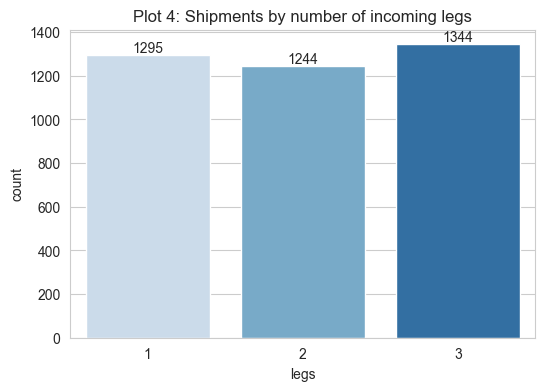

legs
1    33.4
2    32.0
3    34.6
Name: proportion, dtype: float64


In [92]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='legs', data=num, palette='Blues')
for b in ax.patches:
    ax.annotate(int(b.get_height()), (b.get_x() + b.get_width()/2, b.get_height()), ha='center', va='bottom')
plt.title("Plot 4: Shipments by number of incoming legs")
plt.show()
print((num['legs'].value_counts(normalize=True).sort_index() * 100).round(1))

### Plot 5: Pie chart - proportion of Late and OnTime deliveries

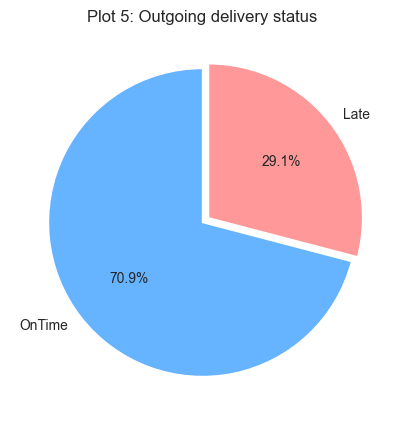

o_status
OnTime    2754
Late      1129
Name: count, dtype: int64


In [93]:
counts = num['o_status'].value_counts()
plt.figure(figsize=(5, 5))
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', colors=['#66b3ff', '#ff9999'], startangle=90, explode=[0, 0.05])
plt.title("Plot 5: Outgoing delivery status")
plt.show()
print(counts)

### Plot 6: Histogram - planned and actual outgoing delivery time

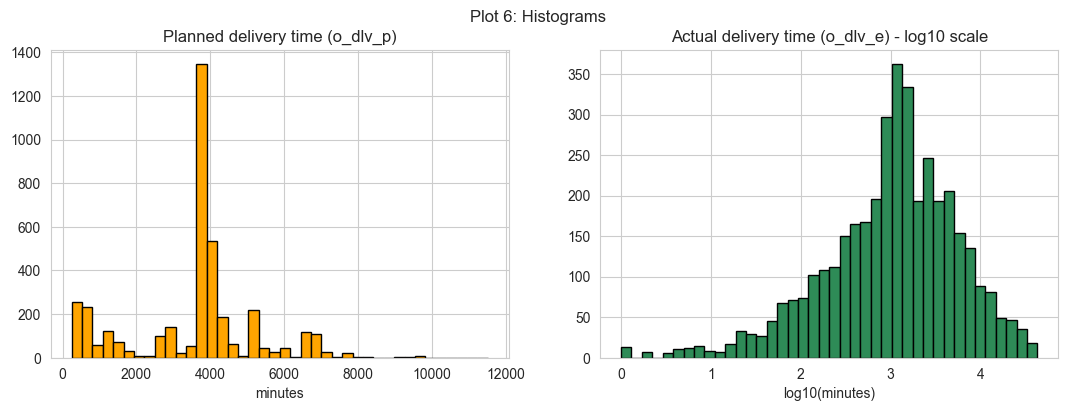

       o_dlv_p  o_dlv_e
count   3883.0   3883.0
mean    3567.4   2985.5
std     1730.0   5134.8
min      240.0      1.0
25%     2880.0    391.0
50%     3780.0   1186.0
75%     4080.0   3101.5
max    11520.0  43161.0
Most common planned times:
 o_dlv_p
3780.0    1229
3960.0     417
4230.0     170
550.0      122
Name: count, dtype: int64


In [94]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(num['o_dlv_p'], bins=40, color='orange', edgecolor='black')
ax[0].set_title("Planned delivery time (o_dlv_p)"); ax[0].set_xlabel("minutes")

ax[1].hist(np.log10(num['o_dlv_e']), bins=40, color='seagreen', edgecolor='black')
ax[1].set_title("Actual delivery time (o_dlv_e) - log10 scale"); ax[1].set_xlabel("log10(minutes)")
plt.suptitle("Plot 6: Histograms")
plt.show()
print(num[['o_dlv_p', 'o_dlv_e']].describe().round(1))
print("Most common planned times:\n", num['o_dlv_p'].value_counts().head(4))

### Plot 7: Box plot - actual delivery time for different number of legs

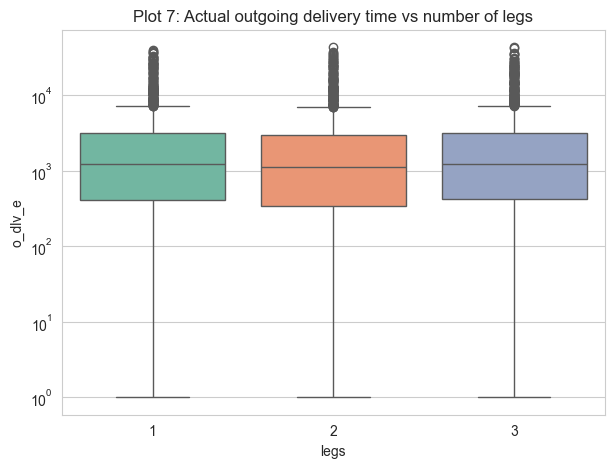

legs
1    1221.0
2    1104.0
3    1232.5
Name: o_dlv_e, dtype: float64


In [95]:
plt.figure(figsize=(7, 5))
sns.boxplot(x='legs', y='o_dlv_e', data=num, palette='Set2')
plt.yscale('log')
plt.title("Plot 7: Actual outgoing delivery time vs number of legs")
plt.show()
print(num.groupby('legs')['o_dlv_e'].median())

### Plot 8: Violin plot - delay of outgoing delivery by number of outgoing hops

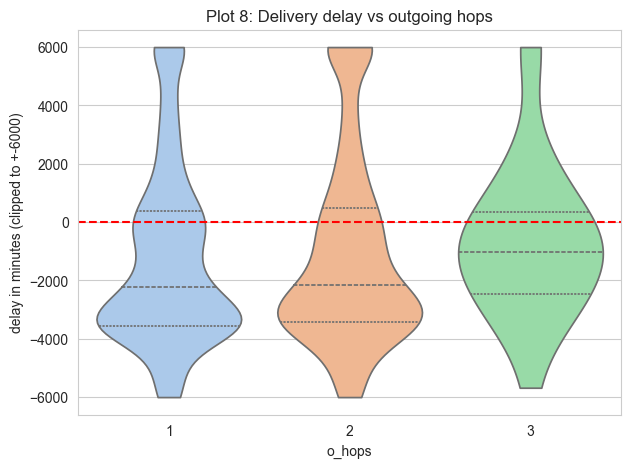

        count  median   mean
o_hops                      
1        2075 -2240.0 -828.3
2        1782 -2155.0 -300.4
3          26 -1028.5 -221.9


In [96]:
plt.figure(figsize=(7, 5))
sns.violinplot(x='o_hops', y=num['o_delay'].clip(-6000, 6000), data=num, palette='pastel', inner='quartile', cut=0)
plt.axhline(0, color='red', linestyle='--')
plt.ylabel("delay in minutes (clipped to +-6000)")
plt.title("Plot 8: Delivery delay vs outgoing hops")
plt.show()
print(num.groupby('o_hops')['o_delay'].agg(['count', 'median', 'mean']).round(1))

### Plot 9: Scatter plot - planned vs actual delivery time

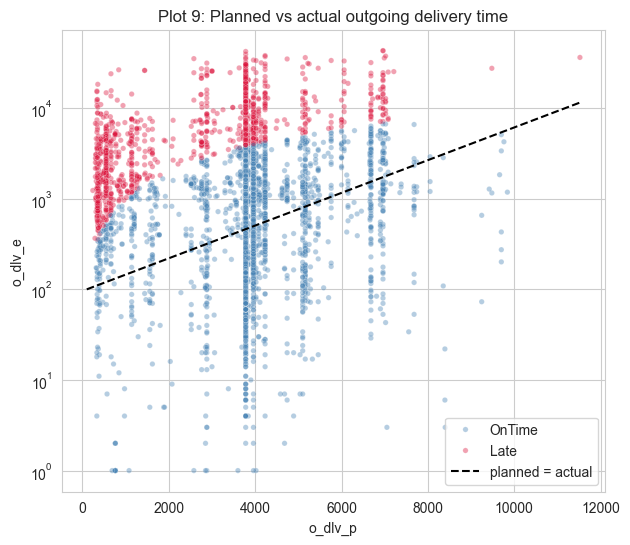

Correlation (Spearman) planned vs actual: 0.048


In [97]:
plt.figure(figsize=(7, 6))
sns.scatterplot(x='o_dlv_p', y='o_dlv_e', hue='o_status', data=num, alpha=0.4, s=15,
                palette={'OnTime': 'steelblue', 'Late': 'crimson'})
plt.yscale('log')
mx = num['o_dlv_p'].max()
plt.plot([100, mx], [100, mx], 'k--', label='planned = actual')
plt.legend()
plt.title("Plot 9: Planned vs actual outgoing delivery time")
plt.show()
print("Correlation (Spearman) planned vs actual:", round(num[['o_dlv_p', 'o_dlv_e']].corr('spearman').iloc[0, 1], 3))

### Plot 10: Heatmap - correlation between the numeric attributes

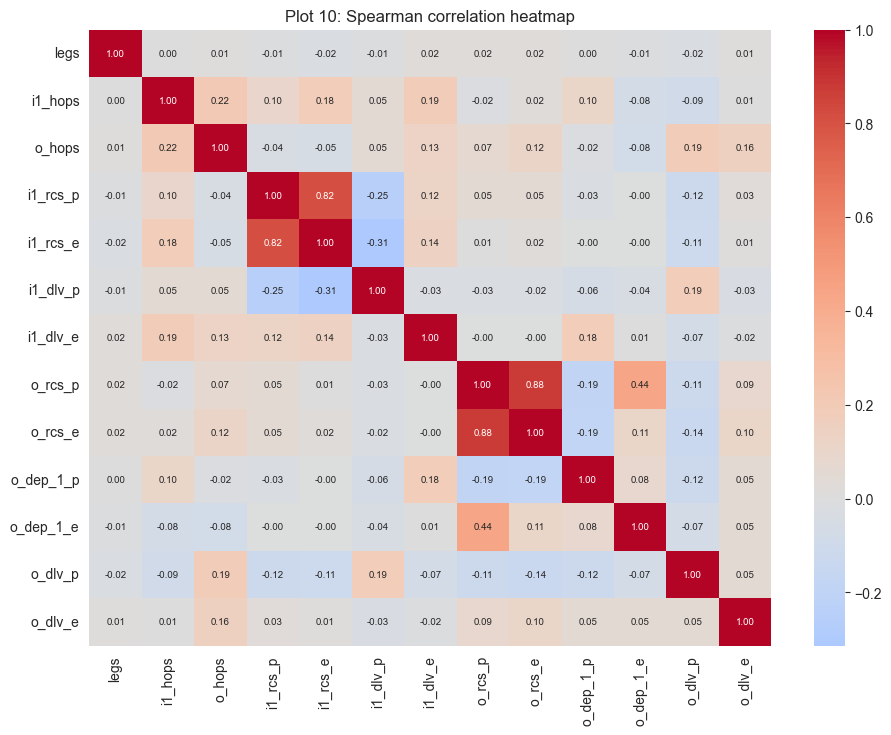

Top 5 positive pairs:
 o_rcs_p   o_rcs_e      0.88
i1_rcs_p  i1_rcs_e     0.82
o_rcs_p   o_dep_1_e    0.44
i1_hops   o_hops       0.22
o_hops    o_dlv_p      0.19
dtype: float64

Strongest negative pair:
 i1_rcs_e  i1_dlv_p   -0.31
dtype: float64


In [98]:
corr = num[['legs','i1_hops','o_hops','i1_rcs_p','i1_rcs_e','i1_dlv_p','i1_dlv_e',
            'o_rcs_p','o_rcs_e','o_dep_1_p','o_dep_1_e','o_dlv_p','o_dlv_e']].corr(method='spearman')

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title("Plot 10: Spearman correlation heatmap")
plt.show()

# strongest pairs
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().dropna().sort_values(ascending=False)
print("Top 5 positive pairs:\n", pairs.head(5).round(2))
print("\nStrongest negative pair:\n", pairs.tail(1).round(2))

### Plot 11: Stacked bar chart - Late % for each planned delivery time group

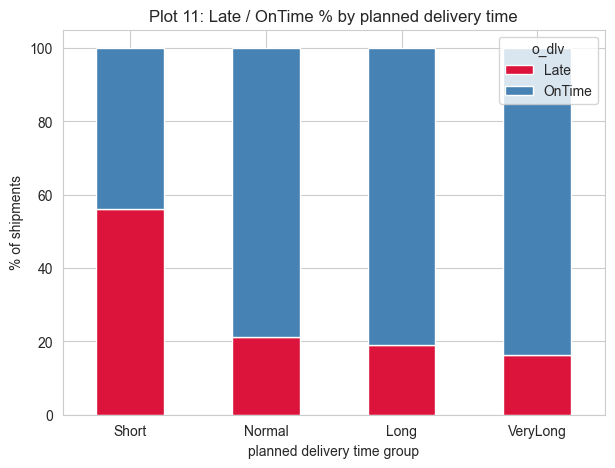

o_dlv       Late  OnTime
o_dlv_plan              
Short       56.2    43.8
Normal      21.1    78.9
Long        18.9    81.1
VeryLong    16.2    83.8


In [99]:
ct = pd.crosstab(ml_all['o_dlv_plan'].str.replace('o_dlv_plan=', ''), y, normalize='index') * 100
ct = ct.loc[['Short', 'Normal', 'Long', 'VeryLong']]
ct.plot(kind='bar', stacked=True, figsize=(7, 5), color=['crimson', 'steelblue'])
plt.ylabel("% of shipments"); plt.xlabel("planned delivery time group"); plt.xticks(rotation=0)
plt.title("Plot 11: Late / OnTime % by planned delivery time")
plt.show()
print(ct.round(1))

### Plot 12: Line plot - Late % of final delivery vs number of late incoming legs

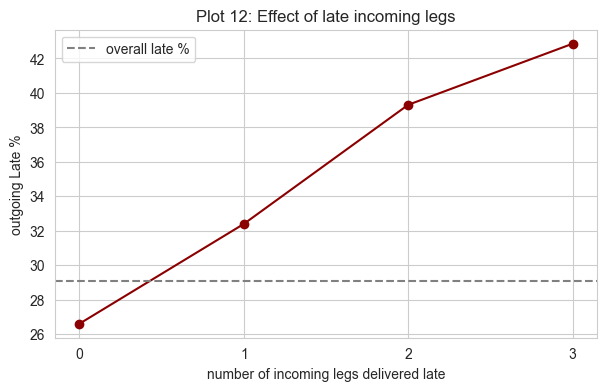

                 late_pct  shipments
n_late_incoming                     
0                    26.6       2681
1                    32.4        849
2                    39.3        290
3                    42.9         63


In [100]:
g = num.groupby('n_late_incoming')['o_status'].agg(late_pct=lambda s: 100 * (s == 'Late').mean(), shipments='count')
plt.figure(figsize=(7, 4))
plt.plot(g.index, g['late_pct'], marker='o', color='darkred')
plt.axhline(100 * (y == 'Late').mean(), color='gray', linestyle='--', label='overall late %')
plt.xticks(g.index); plt.xlabel("number of incoming legs delivered late"); plt.ylabel("outgoing Late %")
plt.legend(); plt.title("Plot 12: Effect of late incoming legs")
plt.show()
print(g.round(1))

### Plot 13: KDE (density) plot - delay of the first incoming leg for Late and OnTime shipments

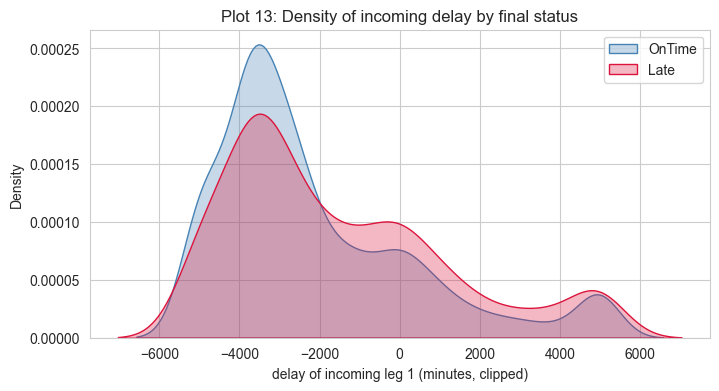

          median    mean
o_status                
Late     -2383.0 -1292.5
OnTime   -2901.5 -1896.5


In [101]:
plt.figure(figsize=(8, 4))
for lab, col in [('OnTime', 'steelblue'), ('Late', 'crimson')]:
    sns.kdeplot(num.loc[num['o_status'] == lab, 'i1_delay'].clip(-5000, 5000), label=lab, color=col, fill=True, alpha=0.3)
plt.xlabel("delay of incoming leg 1 (minutes, clipped)")
plt.title("Plot 13: Density of incoming delay by final status")
plt.legend(); plt.show()
print(num.groupby('o_status')['i1_delay'].agg(['median', 'mean']).round(1))

### Plot 14: Horizontal bar chart - top 10 busiest departure airports of outgoing leg and their Late %

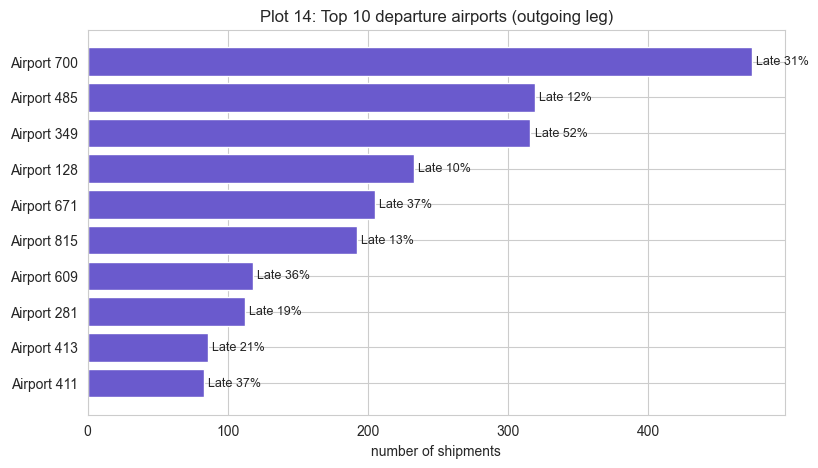

airport  shipments  late_%
    700        474    30.8
    485        319    11.9
    349        316    51.6
    128        233    10.3
    671        205    37.1
    815        192    13.0
    609        118    36.4
    281        112    18.8
    413         86    20.9
    411         83    37.3


In [102]:
top10 = df_sel['o_dep_1_place'].value_counts().head(10)
late_pct = [100 * (y[df_sel['o_dep_1_place'] == p] == 'Late').mean() for p in top10.index]
labels = [f"Airport {p}" for p in top10.index]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(labels[::-1], top10.values[::-1], color='slateblue')
for bar, lp in zip(bars, late_pct[::-1]):
    ax.text(bar.get_width() + 3, bar.get_y() + bar.get_height()/2, f"Late {lp:.0f}%", va='center', fontsize=9)
ax.set_xlabel("number of shipments")
ax.set_title("Plot 14: Top 10 departure airports (outgoing leg)")
plt.show()
print(pd.DataFrame({'airport': top10.index, 'shipments': top10.values, 'late_%': np.round(late_pct, 1)}).to_string(index=False))

### Plot 15: Pair plot - relation between the log transformed durations

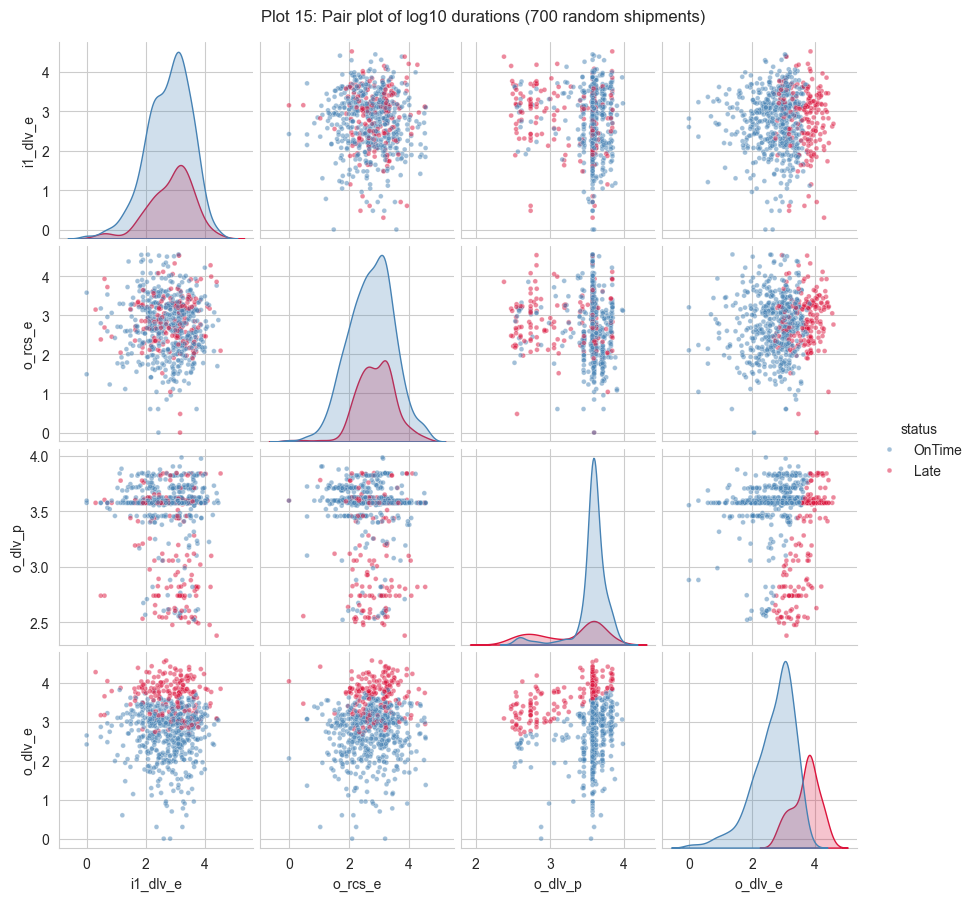

In [103]:
sample = num_log[['i1_dlv_e', 'o_rcs_e', 'o_dlv_p', 'o_dlv_e']].copy()
sample['status'] = num['o_status']
sample = sample.sample(700, random_state=1)

sns.pairplot(sample, hue='status', palette={'OnTime': 'steelblue', 'Late': 'crimson'},
             plot_kws={'alpha': 0.5, 's': 12}, height=2.2)
plt.suptitle("Plot 15: Pair plot of log10 durations (700 random shipments)", y=1.02)
plt.show()

## 4. Predictive Analytics
### 4.1 Association Rules using Apriori
**Assumptions:** min support = 0.10 (itemset must be present in at least 10 % of the shipments) and min confidence = 0.70.

Apriori works level by level: first finds frequent 1-itemsets, joins them to get candidate 2-itemsets, removes (prunes) the candidates whose subset is not frequent, and so on.

In [105]:
from mlxtend.frequent_patterns import apriori, association_rules

min_support = 0.10
min_conf    = 0.70

t0 = time.time()
freq = apriori(basket, min_support=min_support, use_colnames=True)
print("Apriori time: %.3f sec" % (time.time() - t0))

freq['length'] = freq['itemsets'].apply(len)
print("Total frequent itemsets:", len(freq))
print("\nFrequent itemsets by size:")
print(freq['length'].value_counts().sort_index())

print("\nTop 10 frequent itemsets (by support, size >= 2):")
display(freq[freq['length'] >= 2].sort_values('support', ascending=False).head(10))

Apriori time: 0.029 sec
Total frequent itemsets: 1348

Frequent itemsets by size:
length
1     23
2    151
3    362
4    431
5    280
6     87
7     13
8      1
Name: count, dtype: int64

Top 10 frequent itemsets (by support, size >= 2):


,support,itemsets,length
91,0.888231,"frozenset({o_rcs=OnTime, i1_rcs=OnTime})",2
47,0.751738,"frozenset({i1_dlv=OnTime, o_rcs=OnTime})",2
30,0.751223,"frozenset({i1_dlv=OnTime, i1_rcs=OnTime})",2
218,0.712078,"frozenset({i1_dlv=OnTime, o_rcs=OnTime, i1_rcs=OnTime})",3
163,0.675766,"frozenset({o_dlv=OnTime, o_rcs=OnTime})",2
65,0.671131,"frozenset({o_rcs=OnTime, i1_hops=1})",2
84,0.667010,"frozenset({o_dlv=OnTime, i1_rcs=OnTime})",2
48,0.662890,"frozenset({i1_rcs=OnTime, i1_hops=1})",2
297,0.637136,"frozenset({o_rcs=OnTime, i1_hops=1, i1_rcs=OnTime})",3
426,0.636364,"frozenset({o_dlv=OnTime, o_rcs=OnTime, i1_rcs=OnTime})",3


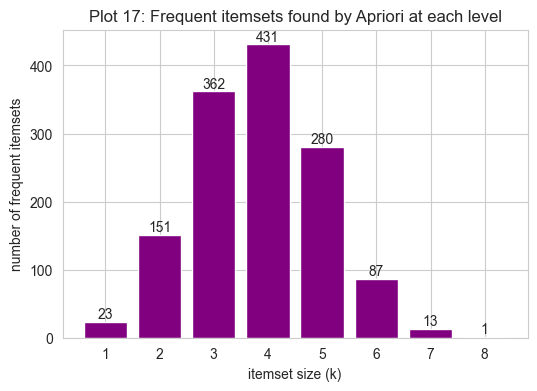

In [106]:
# PLOT 17 : number of frequent itemsets at each level
cnt = freq['length'].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(cnt.index, cnt.values, color='purple')
for i, v in zip(cnt.index, cnt.values):
    plt.text(i, v + 5, str(v), ha='center')
plt.xlabel("itemset size (k)"); plt.ylabel("number of frequent itemsets")
plt.title("Plot 17: Frequent itemsets found by Apriori at each level")
plt.show()

In [107]:
# generating the rules with confidence >= 0.70
rules = association_rules(freq, metric='confidence', min_threshold=min_conf)
rules = rules[rules['lift'] > 1].copy()          # keep only positively related rules
rules['rule'] = rules.apply(lambda r: "IF " + ", ".join(sorted(r['antecedents'])) + "  THEN  " + ", ".join(sorted(r['consequents'])), axis=1)
print("Number of rules (conf >= 0.70, lift > 1):", len(rules))

top_rules = rules.sort_values(['lift', 'confidence'], ascending=False).head(15)
pd.set_option('display.max_colwidth', 120)
display(top_rules[['rule', 'support', 'confidence', 'lift']].round(3).reset_index(drop=True))

Number of rules (conf >= 0.70, lift > 1): 5376


,rule,support,confidence,lift
0,"IF i2_dlv=OnTime, legs=3, o_hops=1 THEN i1_hops=1, i3_dlv=OnTime, o_rcs=OnTime",0.102,0.710,3.837
1,"IF i1_rcs=OnTime, i2_dlv=OnTime, legs=3, o_hops=1 THEN i1_hops=1, i3_dlv=OnTime",0.100,0.740,3.837
2,"IF i3_dlv=OnTime, o_hops=1 THEN i1_hops=1, i2_dlv=OnTime, legs=3, o_rcs=OnTime",0.102,0.708,3.823
3,"IF i1_rcs=OnTime, i3_dlv=OnTime, o_hops=1 THEN i1_hops=1, i2_dlv=OnTime, legs=3",0.100,0.736,3.815
4,"IF i2_dlv=OnTime, legs=3, o_hops=1 THEN i1_hops=1, i1_rcs=OnTime, i3_dlv=OnTime",0.100,0.701,3.815
5,"IF i2_dlv=OnTime, legs=3, o_hops=1, o_rcs=OnTime THEN i1_hops=1, i3_dlv=OnTime",0.102,0.734,3.806
6,"IF i3_dlv=OnTime, o_hops=1, o_rcs=OnTime THEN i1_hops=1, i2_dlv=OnTime, legs=3",0.102,0.734,3.806
7,"IF i2_dlv=OnTime, legs=3, o_hops=1 THEN i1_hops=1, i3_dlv=OnTime",0.105,0.730,3.786
8,"IF i1_dlv=OnTime, i1_rcs=OnTime, legs=3, o_hops=1 THEN i1_hops=1, i3_dlv=OnTime",0.101,0.728,3.775
9,"IF i3_dlv=OnTime, o_hops=1 THEN i1_hops=1, i2_dlv=OnTime, legs=3",0.105,0.728,3.772


In [108]:
freq_low = apriori(basket, min_support=0.03, use_colnames=True)
rules_low = association_rules(freq_low, metric='confidence', min_threshold=0.40)

late_rules = rules_low[rules_low['consequents'] == frozenset({'o_dlv=Late'})].copy()
late_rules = late_rules[late_rules['lift'] > 1.2]
late_rules['rule'] = late_rules['antecedents'].apply(lambda a: "IF " + ", ".join(sorted(a)) + "  THEN  o_dlv=Late")
print("Rules predicting a LATE delivery (support >= 0.03, confidence >= 0.40, lift > 1.2):", len(late_rules))
display(late_rules.sort_values(['lift', 'confidence'], ascending=False)[['rule', 'support', 'confidence', 'lift']].head(12).round(3).reset_index(drop=True))

# and the rules for OnTime with high confidence
ot_rules = rules[rules['consequents'] == frozenset({'o_dlv=OnTime'})]
print("\nRules predicting OnTime delivery (conf>=0.70):", len(ot_rules))
display(ot_rules.sort_values(['confidence', 'lift'], ascending=False)[['rule', 'support', 'confidence', 'lift']].head(6).round(3).reset_index(drop=True))

Rules predicting a LATE delivery (support >= 0.03, confidence >= 0.40, lift > 1.2): 142


,rule,support,confidence,lift
0,"IF i1_rcs=OnTime, o_dlv_plan=Short, o_hops=2, o_rcs=OnTime THEN o_dlv=Late",0.044,0.656,2.257
1,"IF i1_hops=2, i2_dlv=OnTime, o_dlv_plan=Short THEN o_dlv=Late",0.031,0.654,2.250
2,"IF o_dlv_plan=Short, o_hops=2, o_rcs=OnTime THEN o_dlv=Late",0.046,0.644,2.215
3,"IF i1_dlv=OnTime, i1_rcs=OnTime, o_dlv_plan=Short, o_hops=2, o_rcs=OnTime THEN o_dlv=Late",0.031,0.636,2.189
4,"IF i1_rcs=OnTime, o_dlv_plan=Short, o_hops=2 THEN o_dlv=Late",0.050,0.633,2.176
5,"IF i1_dlv=Late, i1_rcs=OnTime, o_dlv_plan=Short, o_rcs=OnTime THEN o_dlv=Late",0.044,0.631,2.170
6,"IF i1_dlv=OnTime, o_dlv_plan=Short, o_hops=2, o_rcs=OnTime THEN o_dlv=Late",0.032,0.628,2.160
7,"IF o_dlv_plan=Short, o_hops=2 THEN o_dlv=Late",0.052,0.623,2.142
8,"IF i1_dlv=Late, o_dlv_plan=Short, o_rcs=OnTime THEN o_dlv=Late",0.048,0.621,2.135
9,"IF i1_dlv=Late, i1_rcs=OnTime, o_dlv_plan=Short THEN o_dlv=Late",0.048,0.619,2.128



Rules predicting OnTime delivery (conf>=0.70): 413


,rule,support,confidence,lift
0,"IF i1_hops=1, i1_rcs=OnTime, o_dlv_plan=Long, o_rcs=OnTime THEN o_dlv=OnTime",0.101,0.844,1.190
1,"IF i1_hops=1, o_dlv_plan=Long, o_rcs=OnTime THEN o_dlv=OnTime",0.106,0.841,1.186
2,"IF i1_dlv=OnTime, o_dlv_plan=VeryLong THEN o_dlv=OnTime",0.118,0.839,1.184
3,"IF i1_dlv=OnTime, i1_rcs=OnTime, o_dlv_plan=VeryLong THEN o_dlv=OnTime",0.111,0.839,1.183
4,"IF i1_dlv=OnTime, i1_rcs=OnTime, o_dlv_plan=VeryLong, o_rcs=OnTime THEN o_dlv=OnTime",0.107,0.839,1.183
5,"IF i1_dlv=OnTime, o_dlv_plan=VeryLong, o_rcs=OnTime THEN o_dlv=OnTime",0.114,0.839,1.183


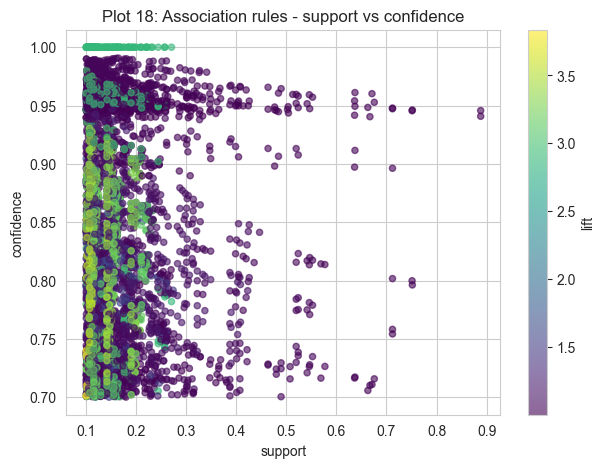

In [109]:
# PLOT 18 : scatter plot of support vs confidence (colour = lift) for all rules
plt.figure(figsize=(7, 5))
sc = plt.scatter(rules['support'], rules['confidence'], c=rules['lift'], cmap='viridis', alpha=0.6, s=20)
plt.colorbar(sc, label='lift')
plt.xlabel("support"); plt.ylabel("confidence")
plt.title("Plot 18: Association rules - support vs confidence")
plt.show()

### 4.2 Naive Bayes Classifier
**Why Naive Bayes and not k-modes?** I have a clear categorical target (`Late` / `OnTime`) and all my attributes are categorical, so a supervised classifier is the best fit. k-modes would be used if there was no target.

**Target:** `o_dlv` (outgoing delivery Late / OnTime).
**Attributes:** the selected attributes from the data transformation step. I did **not** use `o_dlv_e` or anything that is measured after the outgoing delivery, to avoid using the answer to predict the answer (data leakage).

The classifier uses Bayes theorem with the independence assumption:

P(class | x1..xn)  ∝  P(class) × P(x1 | class) × ... × P(xn | class)

I use Laplace smoothing (alpha = 1) so that no probability becomes zero.

In [110]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)

# Select attributes using training-data mutual information
sel_feats = mi[mi >= SEL_THR].index.tolist()

# Final categorical dataset with selected attributes
ml = ml_all[sel_feats].copy()

print("Selected attributes for Naive Bayes:", sel_feats)

# Encode the selected categorical attributes
enc = OrdinalEncoder()
X = enc.fit_transform(ml)

# Use the same training and testing split created earlier
X_train = X[train_idx]
X_test = X[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Train size:", X_train.shape, " Test size:", X_test.shape)

# Train Naive Bayes
nb = CategoricalNB(alpha=1.0)
nb.fit(X_train, y_train)

# Predict test data
y_pred = nb.predict(X_test)

print("Classes:", nb.classes_)
print(
    "Prior probabilities:",
    dict(zip(nb.classes_, np.exp(nb.class_log_prior_).round(3)))
)

Selected attributes for Naive Bayes: ['o_rcs', 'i1_hops', 'i2_dlv', 'i1_dlv', 'o_dep_place', 'o_dlv_plan']
Train size: (3106, 6)  Test size: (777, 6)
Classes: ['Late' 'OnTime']
Prior probabilities: {np.str_('Late'): np.float64(0.291), np.str_('OnTime'): np.float64(0.709)}


In [111]:
# Performance measures
late_idx = list(nb.classes_).index('Late')
y_prob = nb.predict_proba(X_test)[:, late_idx]

print("Accuracy  :", round(accuracy_score(y_test, y_pred), 4))
print("Precision (Late):", round(precision_score(y_test, y_pred, pos_label='Late'), 4))
print("Recall    (Late):", round(recall_score(y_test, y_pred, pos_label='Late'), 4))
print("F1-score  (Late):", round(f1_score(y_test, y_pred, pos_label='Late'), 4))
print("ROC-AUC   :", round(roc_auc_score(y_test == 'Late', y_prob), 4))
print("\nMajority class baseline accuracy:", round((y_test == 'OnTime').mean(), 4))
print("\n", classification_report(y_test, y_pred))
print(
    "5-fold CV accuracy (feature selection within each fold):",
    round(cv_results[SEL_THR], 4)
)

Accuracy  : 0.7709
Precision (Late): 0.6395
Recall    (Late): 0.4867
F1-score  (Late): 0.5528
ROC-AUC   : 0.7287

Majority class baseline accuracy: 0.7091

               precision    recall  f1-score   support

        Late       0.64      0.49      0.55       226
      OnTime       0.81      0.89      0.85       551

    accuracy                           0.77       777
   macro avg       0.72      0.69      0.70       777
weighted avg       0.76      0.77      0.76       777

5-fold CV accuracy (feature selection within each fold): 0.7447


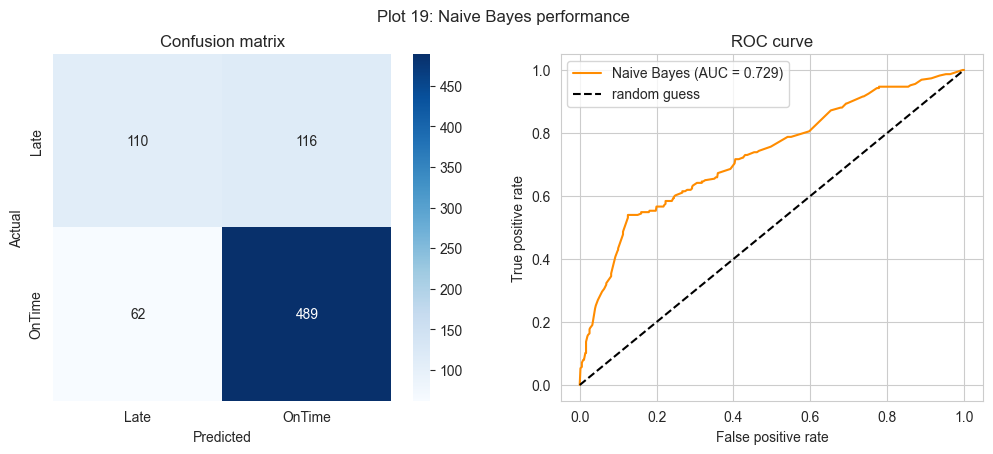

Late predicted correctly: 110 of 226 | OnTime predicted correctly: 489 of 551


In [112]:
# PLOT 19 : confusion matrix heatmap and ROC curve
cm = confusion_matrix(y_test, y_pred, labels=['Late', 'OnTime'])
fpr, tpr, _ = roc_curve(y_test == 'Late', y_prob)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Late', 'OnTime'], yticklabels=['Late', 'OnTime'], ax=ax[0])
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual"); ax[0].set_title("Confusion matrix")

ax[1].plot(fpr, tpr, color='darkorange', label='Naive Bayes (AUC = %.3f)' % roc_auc_score(y_test == 'Late', y_prob))
ax[1].plot([0, 1], [0, 1], 'k--', label='random guess')
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].set_title("ROC curve"); ax[1].legend()
plt.suptitle("Plot 19: Naive Bayes performance")
plt.show()
tn_late = cm[0, 0]; print("Late predicted correctly:", cm[0, 0], "of", cm[0].sum(), "| OnTime predicted correctly:", cm[1, 1], "of", cm[1].sum())

#### IF-THEN rules from the Naive Bayes model
From the learned probabilities, each attribute value gives a rule. For a value `v`, the posterior is  
P(Late | v) = P(Late) P(v | Late) / [ P(Late) P(v | Late) + P(OnTime) P(v | OnTime) ]  
and the rule is "IF attribute = v THEN (Late or OnTime)". I show the rules whose posterior is far from the prior (most informative), only for values covering at least 50 training shipments.

In [113]:
prior = np.exp(nb.class_log_prior_)             # [P(Late), P(OnTime)]
rule_rows = []
for j, feat in enumerate(ml.columns):
    cats = enc.categories_[j]
    lik = np.exp(nb.feature_log_prob_[j])        # shape (2 classes, n_values) = P(value | class)
    for k, val in enumerate(cats):
        joint = prior * lik[:, k]
        post_late = joint[late_idx] / joint.sum()
        coverage = int((X_train[:, j] == k).sum())
        if coverage >= 50:
            pred = 'Late' if post_late > 0.5 else 'OnTime'
            conf = post_late if pred == 'Late' else 1 - post_late
            rule_rows.append([f"IF {val}", f"THEN o_dlv = {pred}", round(conf, 3), round(post_late, 3), coverage])

nb_rules = pd.DataFrame(rule_rows, columns=['IF', 'THEN', 'confidence', 'P(Late|value)', 'coverage'])
nb_rules['gap'] = (nb_rules['P(Late|value)'] - prior[late_idx]).abs()
print("Prior P(Late) =", round(prior[late_idx], 3))
print("\nMost informative rules:")
display(nb_rules.sort_values('gap', ascending=False).head(14).drop(columns='gap').reset_index(drop=True))

Prior P(Late) = 0.291

Most informative rules:


,IF,THEN,confidence,P(Late|value),coverage
0,IF o_dlv_plan=Short,THEN o_dlv = Late,0.548,0.548,831
1,IF o_dep_place=349,THEN o_dlv = Late,0.509,0.509,249
2,IF o_dep_place=128,THEN o_dlv = OnTime,0.897,0.103,181
3,IF o_dep_place=485,THEN o_dlv = OnTime,0.870,0.130,258
4,IF o_dep_place=815,THEN o_dlv = OnTime,0.862,0.138,157
5,IF o_dlv_plan=VeryLong,THEN o_dlv = OnTime,0.833,0.167,560
6,IF o_rcs=Late,THEN o_dlv = OnTime,0.606,0.394,173
7,IF o_dlv_plan=Long,THEN o_dlv = OnTime,0.810,0.190,648
8,IF o_dep_place=671,THEN o_dlv = OnTime,0.633,0.367,161
9,IF o_dlv_plan=Normal,THEN o_dlv = OnTime,0.783,0.217,1067


#### Worked example - how one shipment is classified
Let us take one shipment from the test set and compute the class probabilities by hand using Naive Bayes formula, then check it with the model's output.

In [114]:
i = 0
row = X_test[i]
print("Shipment attributes:", [enc.categories_[j][int(row[j])] for j in range(len(row))])

log_post = nb.class_log_prior_.copy()
for j in range(len(row)):
    log_post += nb.feature_log_prob_[j][:, int(row[j])]      # add log P(value | class)

post = np.exp(log_post - log_post.max()); post = post / post.sum()
print("\nManual calculation  : ", dict(zip(nb.classes_, post.round(4))))
print("Model predict_proba : ", dict(zip(nb.classes_, nb.predict_proba(row.reshape(1, -1))[0].round(4))))
print("Predicted:", nb.classes_[post.argmax()], "| Actual:", y_test.iloc[i])

Shipment attributes: ['o_rcs=OnTime', 'i1_hops=2', 'i2_dlv=OnTime', 'i1_dlv=OnTime', 'o_dep_place=Other', 'o_dlv_plan=Normal']

Manual calculation  :  {np.str_('Late'): np.float64(0.2281), np.str_('OnTime'): np.float64(0.7719)}
Model predict_proba :  {np.str_('Late'): np.float64(0.2281), np.str_('OnTime'): np.float64(0.7719)}
Predicted: OnTime | Actual: OnTime


### 4.3 Closed Frequent Itemsets using COFI algorithm
A frequent itemset is **closed** if no superset of it has the same support. The set of closed frequent itemsets (CFI) is much smaller than the set of all frequent itemsets, but nothing is lost, because the support of any frequent itemset can be got from the closed itemset that contains it.

Same support as Apriori: **min support = 0.10**.

In [115]:
from itertools import combinations
from collections import defaultdict

class Node:
    # node of the FP-tree
    def __init__(self, item, parent):
        self.item = item
        self.parent = parent
        self.count = 0
        self.children = {}

def build_fp_tree(trans_with_counts, order):
    # builds FP-tree and header table (item -> list of nodes)
    root = Node(None, None)
    header = defaultdict(list)
    for items, c in trans_with_counts:
        cur = root
        for it in sorted(items, key=lambda x: order[x]):
            if it not in cur.children:
                child = Node(it, cur)
                cur.children[it] = child
                header[it].append(child)
            cur = cur.children[it]
            cur.count += c
    return root, header

def cofi_closed(transactions, min_count):
    # step 1 : frequent items and their order
    cnt = defaultdict(int)
    for t in transactions:
        for i in set(t):
            cnt[i] += 1
    freq_items = {i: c for i, c in cnt.items() if c >= min_count}
    order = {i: k for k, i in enumerate(sorted(freq_items, key=lambda x: (-freq_items[x], x)))}

    # step 2 : build FP-tree (identical transactions are merged with a count)
    merged = defaultdict(int)
    for t in transactions:
        merged[tuple(sorted([i for i in set(t) if i in freq_items], key=lambda x: order[x]))] += 1
    root, header = build_fp_tree(list(merged.items()), order)

    closed_by_support = defaultdict(list)    # support -> closed itemsets found so far
    result = {}

    # step 3 : least frequent item first
    for x in sorted(freq_items, key=lambda i: -order[i]):
        # COFI-tree of x = all prefix paths of x (items more frequent than x)
        branches = defaultdict(int)
        for node in header[x]:
            path = []
            p = node.parent
            while p.item is not None:
                path.append(p.item)
                p = p.parent
            branches[frozenset(path)] += node.count

        # remove the items which are not frequent with x
        local = defaultdict(int)
        for b, c in branches.items():
            for i in b:
                local[i] += c
        keep_items = {i for i, c in local.items() if c >= min_count}

        # step 4 : candidate patterns from each branch and their supports
        candidates = defaultdict(int)
        for b, c in branches.items():
            b = sorted([i for i in b if i in keep_items], key=lambda i: order[i])
            for r in range(len(b) + 1):
                for comb in combinations(b, r):
                    candidates[frozenset(comb) | {x}] += c

        # step 5 : keep only the closed ones (check the biggest candidates first)
        for s in sorted(candidates, key=len, reverse=True):
            sup = candidates[s]
            if sup < min_count:
                continue
            if any(s < q for q in closed_by_support[sup]):     # a superset with same support exists
                continue
            closed_by_support[sup].append(s)
            result[s] = sup
    return result

n_trans = len(transactions)
min_count = int(np.ceil(min_support * n_trans))

t0 = time.time()
closed = cofi_closed(transactions, min_count)
cofi_time = time.time() - t0
print("COFI time: %.3f sec" % cofi_time)
print("Number of transactions:", n_trans, " | min support count:", min_count)
print("Closed frequent itemsets (CFI):", len(closed))
print("All frequent itemsets (Apriori):", len(freq))
print("Reduction: %.1f %%" % (100 * (1 - len(closed) / len(freq))))

COFI time: 0.714 sec
Number of transactions: 3883  | min support count: 389
Closed frequent itemsets (CFI): 1244
All frequent itemsets (Apriori): 1348
Reduction: 7.7 %


In [116]:
# Verification: compare the COFI output with a direct check on the Apriori result
# (an itemset is closed if no superset has the same support)
sup_dict = {frozenset(s): sp for s, sp in zip(freq['itemsets'], freq['support'])}
by_support = defaultdict(list)
for s, sp in sup_dict.items():
    by_support[round(sp, 10)].append(s)
closed_check = {s for s, sp in sup_dict.items() if not any(s < q for q in by_support[round(sp, 10)])}

print("COFI closed sets == closed sets from Apriori check :", set(closed) == closed_check)
print("Supports are also same :", all(abs(closed[s] / n_trans - sup_dict[s]) < 1e-9 for s in closed))

COFI closed sets == closed sets from Apriori check : True
Supports are also same : True


In [117]:
closed_df = pd.DataFrame([(', '.join(sorted(s)), len(s), c, c / n_trans) for s, c in closed.items()],
                         columns=['closed_itemset', 'size', 'count', 'support'])
print("Closed itemsets by size:"); print(closed_df['size'].value_counts().sort_index().to_string())

print("\nTop 12 closed itemsets with size >= 3 (by support):")
pd.set_option('display.max_colwidth', 130)
display(closed_df[closed_df['size'] >= 3].sort_values('support', ascending=False).head(12).round(3).reset_index(drop=True))

Closed itemsets by size:
size
1     22
2    142
3    335
4    396
5    256
6     80
7     12
8      1

Top 12 closed itemsets with size >= 3 (by support):


,closed_itemset,size,count,support
0,"i1_dlv=OnTime, i1_rcs=OnTime, o_rcs=OnTime",3,2765,0.712
1,"i1_hops=1, i1_rcs=OnTime, o_rcs=OnTime",3,2474,0.637
2,"i1_rcs=OnTime, o_dlv=OnTime, o_rcs=OnTime",3,2471,0.636
3,"i1_dlv=OnTime, o_dlv=OnTime, o_rcs=OnTime",3,2145,0.552
4,"i1_dlv=OnTime, i1_rcs=OnTime, o_dlv=OnTime",3,2123,0.547
5,"i1_dlv=OnTime, i1_hops=1, o_rcs=OnTime",3,2120,0.546
6,"i1_dlv=OnTime, i1_hops=1, i1_rcs=OnTime",3,2103,0.542
7,"i1_dlv=OnTime, i1_rcs=OnTime, o_dlv=OnTime, o_rcs=OnTime",4,2034,0.524
8,"i1_dlv=OnTime, i1_hops=1, i1_rcs=OnTime, o_rcs=OnTime",4,2018,0.520
9,"i1_hops=1, o_dlv=OnTime, o_rcs=OnTime",3,1901,0.490


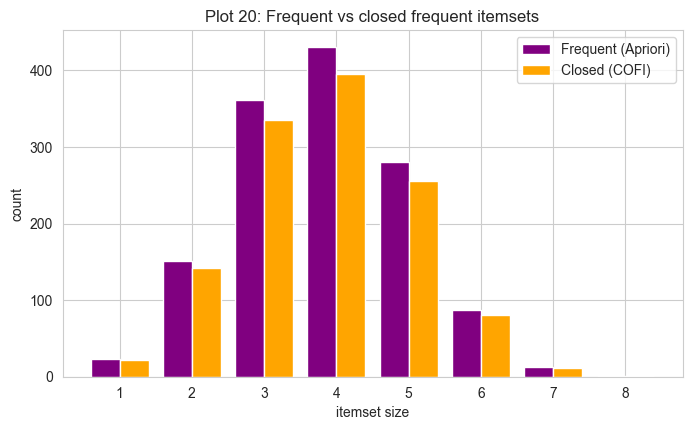

In [118]:
# PLOT 20 : all frequent vs closed frequent itemsets (size wise)
a = freq['length'].value_counts().sort_index()
c = closed_df['size'].value_counts().sort_index().reindex(a.index, fill_value=0)
x = np.arange(len(a))
plt.figure(figsize=(8, 4.5))
plt.bar(x - 0.2, a.values, 0.4, label='Frequent (Apriori)', color='purple')
plt.bar(x + 0.2, c.values, 0.4, label='Closed (COFI)', color='orange')
plt.xticks(x, a.index); plt.xlabel("itemset size"); plt.ylabel("count"); plt.legend()
plt.title("Plot 20: Frequent vs closed frequent itemsets")
plt.show()

#### Closed association rules

Min confidence = 0.70 (same as Apriori).

In [119]:
closed_list = sorted(closed.items(), key=lambda kv: len(kv[0]))

def support_of(itemset):
    # support of any frequent itemset = largest support among closed supersets (its closure)
    return max(sup for s, sup in closed_list if itemset <= s)

crules = []
for A, sa in closed_list:
    for Z, sz in closed_list:
        if len(Z) > len(A) and A < Z:
            conf = sz / sa
            if conf >= min_conf:
                cons = Z - A
                lift = conf / (support_of(cons) / n_trans)
                if lift > 1:
                    crules.append((A, cons, sz / n_trans, conf, lift))

closed_rules = pd.DataFrame(crules, columns=['antecedent', 'consequent', 'support', 'confidence', 'lift'])
closed_rules['rule'] = closed_rules.apply(lambda r: "IF " + ", ".join(sorted(r['antecedent'])) + "  THEN  " + ", ".join(sorted(r['consequent'])), axis=1)

print("Closed association rules (conf >= 0.70, lift > 1):", len(closed_rules))
print("Association rules from Apriori (same thresholds) :", len(rules))
display(closed_rules.sort_values(['lift', 'confidence'], ascending=False)[['rule', 'support', 'confidence', 'lift']].head(12).round(3).reset_index(drop=True))

Closed association rules (conf >= 0.70, lift > 1): 4267
Association rules from Apriori (same thresholds) : 5376


,rule,support,confidence,lift
0,"IF i2_dlv=OnTime, legs=3, o_hops=1 THEN i1_hops=1, i3_dlv=OnTime, o_rcs=OnTime",0.102,0.710,3.837
1,"IF i1_rcs=OnTime, i2_dlv=OnTime, legs=3, o_hops=1 THEN i1_hops=1, i3_dlv=OnTime",0.100,0.740,3.837
2,"IF i2_dlv=OnTime, legs=3, o_hops=1 THEN i1_hops=1, i1_rcs=OnTime, i3_dlv=OnTime",0.100,0.701,3.815
3,"IF i2_dlv=OnTime, legs=3, o_hops=1, o_rcs=OnTime THEN i1_hops=1, i3_dlv=OnTime",0.102,0.734,3.806
4,"IF i2_dlv=OnTime, legs=3, o_hops=1 THEN i1_hops=1, i3_dlv=OnTime",0.105,0.730,3.786
5,"IF i1_dlv=OnTime, i1_rcs=OnTime, legs=3, o_hops=1 THEN i1_hops=1, i3_dlv=OnTime",0.101,0.728,3.775
6,"IF i1_dlv=OnTime, legs=3, o_hops=1, o_rcs=OnTime THEN i1_hops=1, i3_dlv=OnTime",0.102,0.724,3.753
7,"IF i1_dlv=OnTime, legs=3, o_hops=1 THEN i1_hops=1, i3_dlv=OnTime",0.105,0.720,3.730
8,"IF i1_hops=1, i1_rcs=OnTime, i2_dlv=OnTime, legs=3, o_dlv=OnTime THEN i1_dlv=OnTime, i3_dlv=OnTime, o_rcs=OnTime",0.107,0.794,3.597
9,"IF i1_hops=1, i2_dlv=OnTime, legs=3, o_dlv=OnTime THEN i1_dlv=OnTime, i1_rcs=OnTime, i3_dlv=OnTime, o_rcs=OnTime",0.107,0.754,3.586


## 5. PySpark Test Drive and Performance Comparison
I test two techniques in PySpark:
1. **Association rule mining** - PySpark MLlib does not have Apriori, it has **FP-Growth** which is its distributed frequent itemset algorithm (same output - the frequent itemsets and rules). I compare it with the normal single machine `mlxtend` Apriori / FP-Growth.
2. **Naive Bayes classifier** - PySpark MLlib `NaiveBayes` vs scikit-learn `CategoricalNB`.

In [120]:
import os
import sys

# Use the same Python interpreter for Spark workers
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

print("Python executable:", sys.executable)

Python executable: c:\Users\Sai Pranathi\AppData\Local\Programs\Python\Python311\python.exe


In [121]:
import os
from pyspark.sql import SparkSession

spark = (SparkSession.builder.master("local[*]").appName("Cargo2000")
         .config("spark.driver.memory", "2g")
         .config("spark.ui.enabled", "false")
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

print("Spark version :", spark.version)
print("CPU cores of this machine :", os.cpu_count())
print("Spark default parallelism :", spark.sparkContext.defaultParallelism)

Spark version : 4.3.0
CPU cores of this machine : 12
Spark default parallelism : 12


### 5.1 Association rules (FP-Growth) in PySpark

In [122]:
from pyspark.ml.fpm import FPGrowth
from mlxtend.frequent_patterns import fpgrowth

# base spark dataframe with one array of items per shipment
base_items = spark.createDataFrame([(i, items) for i, items in enumerate(transactions)], ['id', 'items'])

# --- first, check that spark gives the same result at k = 1
model = FPGrowth(itemsCol='items', minSupport=min_support, minConfidence=min_conf).fit(base_items)
spark_freq = model.freqItemsets.toPandas()
print("Frequent itemsets from Spark FP-Growth :", len(spark_freq))
print("Frequent itemsets from Apriori (python):", len(freq))
same = {frozenset(i) for i in spark_freq['items']} == {frozenset(s) for s in freq['itemsets']}
print("Both give exactly the same itemsets:", same)
print("Association rules from Spark (conf >= 0.70):", model.associationRules.count())

Frequent itemsets from Spark FP-Growth : 1348
Frequent itemsets from Apriori (python): 1348
Both give exactly the same itemsets: True
Association rules from Spark (conf >= 0.70): 3125


In [123]:
results_arm = []
for k in [1, 10, 50, 100, 200]:
    # python side: repeat the transactions k times
    B = pd.DataFrame(np.tile(basket.values, (k, 1)), columns=basket.columns)

    t0 = time.time(); f1 = apriori(B, min_support=min_support, use_colnames=True);   t_apriori = time.time() - t0
    t0 = time.time(); f2 = fpgrowth(B, min_support=min_support, use_colnames=True); t_fpg = time.time() - t0

    # spark side: repeat the rows k times inside spark
    sdf = base_items.crossJoin(spark.range(k).withColumnRenamed('id', 'rep')).drop('rep').repartition(8).cache()
    n_rows = sdf.count()                                        # forces caching, not timed
    t0 = time.time()
    m_k = FPGrowth(itemsCol='items', minSupport=min_support, minConfidence=min_conf).fit(sdf)
    n_sp = m_k.freqItemsets.count()
    t_spark = time.time() - t0
    sdf.unpersist()

    results_arm.append([k, n_rows, round(t_apriori, 3), round(t_fpg, 3), round(t_spark, 3), len(f1), n_sp])
    print(f"k={k:<4} rows={n_rows:<7} apriori={t_apriori:.2f}s  python-fpgrowth={t_fpg:.2f}s  spark-fpgrowth={t_spark:.2f}s")

res_arm = pd.DataFrame(results_arm, columns=['k', 'rows', 'apriori_s', 'python_fpgrowth_s', 'spark_fpgrowth_s', 'itemsets_python', 'itemsets_spark'])
res_arm['speedup_vs_apriori'] = (res_arm['apriori_s'] / res_arm['spark_fpgrowth_s']).round(2)
res_arm['speedup_vs_python_fpg'] = (res_arm['python_fpgrowth_s'] / res_arm['spark_fpgrowth_s']).round(2)
display(res_arm)

k=1    rows=3883    apriori=0.10s  python-fpgrowth=0.21s  spark-fpgrowth=2.10s
k=10   rows=38830   apriori=0.53s  python-fpgrowth=0.95s  spark-fpgrowth=4.43s
k=50   rows=194150  apriori=2.70s  python-fpgrowth=5.33s  spark-fpgrowth=5.70s
k=100  rows=388300  apriori=5.22s  python-fpgrowth=8.77s  spark-fpgrowth=6.43s
k=200  rows=776600  apriori=10.42s  python-fpgrowth=17.16s  spark-fpgrowth=9.41s


,k,rows,apriori_s,python_fpgrowth_s,spark_fpgrowth_s,itemsets_python,itemsets_spark,speedup_vs_apriori,speedup_vs_python_fpg
0,1,3883,0.099,0.211,2.100,1348,1348,0.05,0.10
1,10,38830,0.535,0.947,4.431,1348,1348,0.12,0.21
2,50,194150,2.702,5.328,5.701,1348,1348,0.47,0.93
3,100,388300,5.217,8.774,6.429,1348,1348,0.81,1.36
4,200,776600,10.421,17.165,9.406,1348,1348,1.11,1.82


### 5.2 Naive Bayes in PySpark

In [124]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import NaiveBayes
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# same train / test split as before
train_idx, test_idx = train_test_split(np.arange(len(ml)), test_size=0.2, stratify=y, random_state=42)
train_pd = ml.iloc[train_idx].copy(); train_pd['label'] = y.iloc[train_idx].values
test_pd  = ml.iloc[test_idx].copy();  test_pd['label']  = y.iloc[test_idx].values

train_sdf = spark.createDataFrame(train_pd)
test_sdf  = spark.createDataFrame(test_pd)

def make_pipeline():
    idx  = [StringIndexer(inputCol=c, outputCol=c + '_i', handleInvalid='keep') for c in ml.columns]
    ohe  = OneHotEncoder(inputCols=[c + '_i' for c in ml.columns], outputCols=[c + '_v' for c in ml.columns], dropLast=False)
    vec  = VectorAssembler(inputCols=[c + '_v' for c in ml.columns], outputCol='features')
    lab  = StringIndexer(inputCol='label', outputCol='label_i')
    nbs  = NaiveBayes(featuresCol='features', labelCol='label_i', modelType='multinomial', smoothing=1.0)
    return Pipeline(stages=idx + [ohe, vec, lab, nbs])

# --- accuracy check on the normal (k=1) data
spark_model = make_pipeline().fit(train_sdf)
pred = spark_model.transform(test_sdf)
ev = MulticlassClassificationEvaluator(labelCol='label_i', predictionCol='prediction')
print("Spark NaiveBayes accuracy :", round(ev.setMetricName('accuracy').evaluate(pred), 4))
print("Spark NaiveBayes weighted F1:", round(ev.setMetricName('f1').evaluate(pred), 4))
print("sklearn CategoricalNB accuracy:", round(accuracy_score(y_test, y_pred), 4))

Spark NaiveBayes accuracy : 0.7709
Spark NaiveBayes weighted F1: 0.7607
sklearn CategoricalNB accuracy: 0.7709


In [125]:
results_nb = []
for k in [1, 10, 50, 100, 200]:
    # sklearn side : encode + fit on k times repeated training data
    big_train = pd.concat([train_pd] * k, ignore_index=True)
    t0 = time.time()
    enc_k = OrdinalEncoder()
    Xk = enc_k.fit_transform(big_train[ml.columns])
    CategoricalNB().fit(Xk, big_train['label'])
    t_sk = time.time() - t0

    # spark side : index + one-hot + fit on k times repeated training data
    sk_df = train_sdf.crossJoin(spark.range(k).withColumnRenamed('id', 'rep')).drop('rep').repartition(8).cache()
    n_rows = sk_df.count()                                      # not timed
    t0 = time.time()
    m_nb = make_pipeline().fit(sk_df)
    t_sp = time.time() - t0
    acc_sp = ev.setMetricName('accuracy').evaluate(m_nb.transform(test_sdf))
    sk_df.unpersist()

    results_nb.append([k, n_rows, round(t_sk, 3), round(t_sp, 3), round(acc_sp, 4)])
    print(f"k={k:<4} rows={n_rows:<7} sklearn={t_sk:.2f}s  spark={t_sp:.2f}s")

res_nb = pd.DataFrame(results_nb, columns=['k', 'train_rows', 'sklearn_s', 'spark_s', 'spark_accuracy'])
res_nb['speedup (sklearn/spark)'] = (res_nb['sklearn_s'] / res_nb['spark_s']).round(2)
display(res_nb)

k=1    rows=3106    sklearn=0.06s  spark=6.34s
k=10   rows=31060   sklearn=0.37s  spark=6.77s
k=50   rows=155300  sklearn=1.99s  spark=6.57s
k=100  rows=310600  sklearn=3.69s  spark=8.11s
k=200  rows=621200  sklearn=7.67s  spark=9.89s


,k,train_rows,sklearn_s,spark_s,spark_accuracy,speedup (sklearn/spark)
0,1,3106,0.059,6.341,0.7709,0.01
1,10,31060,0.371,6.769,0.7709,0.05
2,50,155300,1.986,6.571,0.7709,0.30
3,100,310600,3.689,8.108,0.7709,0.45
4,200,621200,7.665,9.885,0.7709,0.78


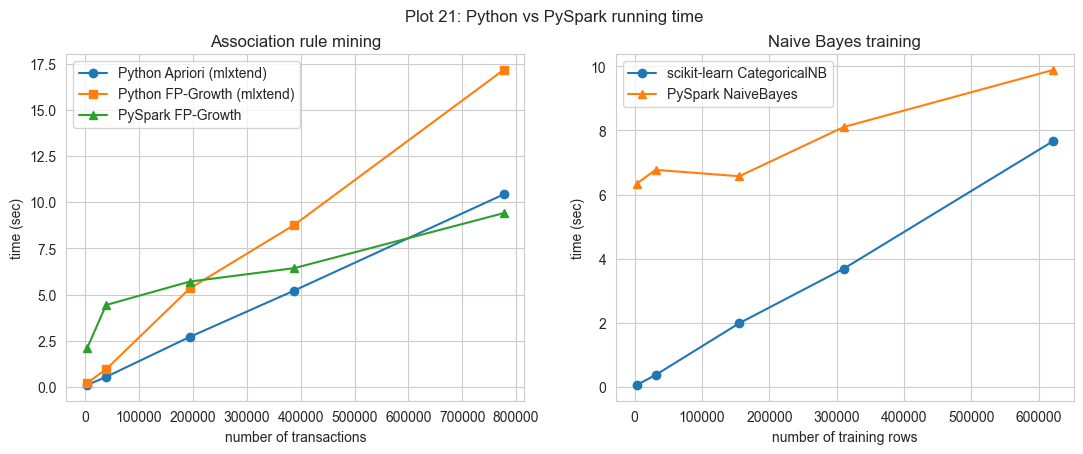

In [126]:
# PLOT 21 : running time comparison
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(res_arm['rows'], res_arm['apriori_s'], 'o-', label='Python Apriori (mlxtend)')
ax[0].plot(res_arm['rows'], res_arm['python_fpgrowth_s'], 's-', label='Python FP-Growth (mlxtend)')
ax[0].plot(res_arm['rows'], res_arm['spark_fpgrowth_s'], '^-', label='PySpark FP-Growth')
ax[0].set_title("Association rule mining"); ax[0].set_xlabel("number of transactions"); ax[0].set_ylabel("time (sec)"); ax[0].legend()

ax[1].plot(res_nb['train_rows'], res_nb['sklearn_s'], 'o-', label='scikit-learn CategoricalNB')
ax[1].plot(res_nb['train_rows'], res_nb['spark_s'], '^-', label='PySpark NaiveBayes')
ax[1].set_title("Naive Bayes training"); ax[1].set_xlabel("number of training rows"); ax[1].set_ylabel("time (sec)"); ax[1].legend()

plt.suptitle("Plot 21: Python vs PySpark running time")
plt.show()

In [127]:
spark.stop()